# 

### Marketing Campaign Analysis


#### Author: Tomiwa Richard

##### Tools Used

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn

### Project overview
This project analyzed 2,214 customer records to understand purchasing behavior, identify high-value customers, evaluate campaign effectiveness, and generate data-driven marketing recommendations. Results showed that income is the strongest predictor of spending, wine products generate the highest revenue, and campaign responders tend to be higher-income customers with greater overall spending.

### Business question

| KPI                           | Value      |
| ----------------------------- | ---------- |
| Customers Analyzed            | 2,214      |
| Average Income                | $51,958    |
| Average Customer Age          | 46         |
| Highest Spending Category     | Wine       |
| Most Popular Channel          | Store      |
| Best Campaign Acceptance Rate | Campaign 5 |


In [52]:
# Importing libraries
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Load the dataset
df = pd.read_excel(r"data/marketing_campaign.xlsx",)

In [54]:
# Check the first 5 rows
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


Check the shape of the data

In [55]:
df.shape

(2240, 29)

The dataset contains 2240 customers and 29 columns covering customer demographics, 
spending behavior, purchase channels, and campaign responses.

In [56]:
# See all column names
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')

In [57]:
# Check data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [58]:
# Check basic statistics
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


## Step 2 — Data Cleaning

Before we analyze the data, we need to clean it. Raw data always has issues 
that can distort our analysis if we don't fix them first.

In this dataset we identified four issues during inspection:
1. 24 missing values in the Income column
2. A customer with birth year 1893 — clearly a data entry error
3. A customer with income of 666,666 — an obvious outlier and likely an error
4. Two useless columns — Z_CostContact and Z_Revenue have the same value 
   for every customer and provide no analytical value

We will fix all four issues before moving forward.

In [59]:
# Drop rows with missing Income
df = df.dropna(subset=['Income'])

# Remove the 1893 birth year outlier
df = df[df['Year_Birth'] != 1893]

# Remove the income outlier of 666,666
df = df[df['Income'] < 600000]

# Drop useless columns
df = df.drop(columns=['Z_CostContact', 'Z_Revenue'])

# Confirm the result
print(df.shape)

(2214, 27)


After cleaning, we removed 26 rows with errors or missing data and dropped 
2 irrelevant columns. The dataset now has 27 columns ready for analysis.

## Step 3 — Feature Engineering

The raw columns don't tell the full story on their own. We need to create 
new columns that are more meaningful for our analysis.

We will create:
- Age — more useful than Year_Birth for understanding our customers
- TotalSpend — total amount each customer spent across all products
- TotalPurchases — total number of purchases across all channels
- FamilySize — number of children and teenagers at home combined
- AcceptedAnyCampaign — whether a customer accepted any of the 5 previous campaigns
- Customer_Days: how long each customer has been with the company
- HasChildren: whether a customer has any children at home
- Marital_Status cleaned up into two simple groups — Single or Partner


In [60]:
# Create Age column
df['Age'] = 2015 - df['Year_Birth']

# Create TotalSpend column
df['TotalSpend'] = df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] + df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds']

# Create TotalPurchases column
df['TotalPurchases'] = df['NumWebPurchases'] + df['NumCatalogPurchases'] + df['NumStorePurchases']

# Create FamilySize column
df['FamilySize'] = df['Kidhome'] + df['Teenhome']

# Create AcceptedAnyCampaign column
df['AcceptedAnyCampaign'] = df[['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']].max(axis=1)

# Confirm new columns were created
df[['Age', 'TotalSpend', 'TotalPurchases', 'FamilySize', 'AcceptedAnyCampaign']].head()

# Convert Dt_Customer to a proper date
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'])

# Create Customer_Days — days since they became a customer
last_date = df['Dt_Customer'].max()
df['Customer_Days'] = (last_date - df['Dt_Customer']).dt.days

# Create HasChildren column
df['HasChildren'] = (df['FamilySize'] > 0).astype(int)

# Clean up Marital_Status into two groups
df['Marital_Status'] = df['Marital_Status'].replace({
    'Married': 'Partner',
    'Together': 'Partner',
    'Single': 'Single',
    'Divorced': 'Single',
    'Widow': 'Single',
    'Alone': 'Single',
    'Absurd': 'Single',
    'YOLO': 'Single'
})

# Confirm
df[['Dt_Customer', 'Customer_Days', 'HasChildren', 'Marital_Status']].head()

,Dt_Customer,Customer_Days,HasChildren,Marital_Status
0,2012-09-04,663,0,Single
1,2014-03-08,113,1,Single
2,2013-08-21,312,0,Partner
3,2014-02-10,139,1,Partner
4,2014-01-19,161,1,Partner


We added Customer_Days to measure customer loyalty, HasChildren to easily 
compare parents vs non-parents, and simplified Marital_Status into two 
clean groups — Single and Partner — removing nonsensical entries.

In [61]:
# Check unique values in Education
print(df['Education'].unique())

# Check unique values in Marital_Status to confirm our cleaning worked
print(df['Marital_Status'].unique())

['Graduation' 'PhD' 'Master' 'Basic' '2n Cycle']
['Single' 'Partner']


In [62]:
# Check all columns now available
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Response', 'Age', 'TotalSpend',
       'TotalPurchases', 'FamilySize', 'AcceptedAnyCampaign', 'Customer_Days',
       'HasChildren'],
      dtype='object')

In [63]:
# Standardize column names — lowercase and replace spaces with underscores
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Standardize all text columns
df['education'] = df['education'].str.strip().str.title()
df['marital_status'] = df['marital_status'].str.strip().str.title()

# Confirm column names
print(df.columns)
print()
# Confirm text columns
print(df['education'].unique())
print(df['marital_status'].unique())

Index(['id', 'year_birth', 'education', 'marital_status', 'income', 'kidhome',
       'teenhome', 'dt_customer', 'recency', 'mntwines', 'mntfruits',
       'mntmeatproducts', 'mntfishproducts', 'mntsweetproducts',
       'mntgoldprods', 'numdealspurchases', 'numwebpurchases',
       'numcatalogpurchases', 'numstorepurchases', 'numwebvisitsmonth',
       'acceptedcmp3', 'acceptedcmp4', 'acceptedcmp5', 'acceptedcmp1',
       'acceptedcmp2', 'complain', 'response', 'age', 'totalspend',
       'totalpurchases', 'familysize', 'acceptedanycampaign', 'customer_days',
       'haschildren'],
      dtype='object')

['Graduation' 'Phd' 'Master' 'Basic' '2N Cycle']
['Single' 'Partner']


In [64]:
# Check all current column names
df.columns

Index(['id', 'year_birth', 'education', 'marital_status', 'income', 'kidhome',
       'teenhome', 'dt_customer', 'recency', 'mntwines', 'mntfruits',
       'mntmeatproducts', 'mntfishproducts', 'mntsweetproducts',
       'mntgoldprods', 'numdealspurchases', 'numwebpurchases',
       'numcatalogpurchases', 'numstorepurchases', 'numwebvisitsmonth',
       'acceptedcmp3', 'acceptedcmp4', 'acceptedcmp5', 'acceptedcmp1',
       'acceptedcmp2', 'complain', 'response', 'age', 'totalspend',
       'totalpurchases', 'familysize', 'acceptedanycampaign', 'customer_days',
       'haschildren'],
      dtype='object')

In [65]:
# Rename columns to be clearer and more descriptive
df = df.rename(columns={
    'dt_customer': 'enrollment_date',
    'recency': 'recency_days',
    'mntwines': 'spent_wines',
    'mntfruits': 'spent_fruits',
    'mntmeatproducts': 'spent_meat',
    'mntfishproducts': 'spent_fish',
    'mntsweetproducts': 'spent_sweets',
    'mntgoldprods': 'spent_gold',
    'numdealspurchases': 'deals_purchases',
    'numwebpurchases': 'web_purchases',
    'numcatalogpurchases': 'catalog_purchases',
    'numstorepurchases': 'store_purchases',
    'numwebvisitsmonth': 'web_visits_month',
    'acceptedcmp1': 'campaign_1',
    'acceptedcmp2': 'campaign_2',
    'acceptedcmp3': 'campaign_3',
    'acceptedcmp4': 'campaign_4',
    'acceptedcmp5': 'campaign_5',
    'acceptedanycampaign': 'any_campaign'
})

# Confirm
df.columns

Index(['id', 'year_birth', 'education', 'marital_status', 'income', 'kidhome',
       'teenhome', 'enrollment_date', 'recency_days', 'spent_wines',
       'spent_fruits', 'spent_meat', 'spent_fish', 'spent_sweets',
       'spent_gold', 'deals_purchases', 'web_purchases', 'catalog_purchases',
       'store_purchases', 'web_visits_month', 'campaign_3', 'campaign_4',
       'campaign_5', 'campaign_1', 'campaign_2', 'complain', 'response', 'age',
       'totalspend', 'totalpurchases', 'familysize', 'any_campaign',
       'customer_days', 'haschildren'],
      dtype='object')

All columns are now clearly named and consistent. 
The dataset is clean and ready for analysis.

## Final Check on Cleaned Dataset

Now that the data is fully cleaned, renamed, and enriched with new features,
we do a final check to confirm everything looks correct before we start analyzing.

In [66]:
# Check shape
print('Shape:', df.shape)
print()

# Check for any remaining missing values
print('Missing Values:')
print(df.isnull().sum()[df.isnull().sum() > 0])
print()

# Check statistics look sensible
df.describe()

Shape: (2214, 34)

Missing Values:
Series([], dtype: int64)



,id,year_birth,income,kidhome,teenhome,enrollment_date,recency_days,spent_wines,spent_fruits,spent_meat,...,campaign_2,complain,response,age,totalspend,totalpurchases,familysize,any_campaign,customer_days,haschildren
count,2214.000000,2214.000000,2214.000000,2214.000000,2214.000000,2214,2214.000000,2214.000000,2214.000000,2214.000000,...,2214.00000,2214.000000,2214.000000,2214.000000,2214.000000,2214.000000,2214.000000,2214.000000,2214.000000,2214.000000
mean,5584.171183,1968.850949,51966.152213,0.441734,0.505420,2013-07-10 08:32:31.219512320,49.036134,305.359530,26.373532,167.136405,...,0.01355,0.009485,0.150407,46.149051,607.585818,12.564137,0.947154,0.207317,353.644083,0.714092
min,0.000000,1899.000000,1730.000000,0.000000,0.000000,2012-07-30 00:00:00,0.000000,0.000000,0.000000,0.000000,...,0.00000,0.000000,0.000000,19.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2814.250000,1959.000000,35265.000000,0.000000,0.000000,2013-01-16 00:00:00,24.000000,24.000000,2.000000,16.000000,...,0.00000,0.000000,0.000000,38.000000,69.000000,6.000000,0.000000,0.000000,180.000000,0.000000
50%,5454.500000,1970.000000,51371.000000,0.000000,0.000000,2013-07-08 12:00:00,49.000000,175.500000,8.000000,68.000000,...,0.00000,0.000000,0.000000,45.000000,397.000000,12.000000,1.000000,0.000000,355.500000,1.000000
75%,8417.500000,1977.000000,68487.000000,1.000000,1.000000,2013-12-31 00:00:00,74.000000,505.000000,33.000000,232.750000,...,0.00000,0.000000,0.000000,56.000000,1048.000000,18.000000,1.000000,0.000000,529.000000,1.000000
max,11191.000000,1996.000000,162397.000000,2.000000,2.000000,2014-06-29 00:00:00,99.000000,1493.000000,199.000000,1725.000000,...,1.00000,1.000000,1.000000,116.000000,2525.000000,32.000000,3.000000,1.000000,699.000000,1.000000
std,3247.774914,11.880844,21530.475146,0.536926,0.544219,NaN,28.950861,337.362404,39.807082,224.335771,...,0.11564,0.096950,0.357550,11.880844,602.933072,7.204030,0.749399,0.405476,202.416834,0.451948


The dataset is fully cleaned with no missing values. 
All columns are correctly typed, named, and ready for analysis.
We have 2214 customers and 34 columns including our 7 engineered features.

In [67]:
# Save cleaned dataset
#df.to_csv(r'C:\Users\DELL\Downloads\Customer analytics for Marketing optimization\marketing_campaign_cleaned.csv', index=False)
# Remove age outliers
#df = df[df['age'] < 100]

# Overwrite the saved CSV with corrected data
#df.to_csv(r'C:\Users\DELL\Downloads\Customer analytics for Marketing optimization\marketing_campaign_cleaned.csv', index=False)

# Confirm
#print('New shape:', df.shape)
#print('Max age:', df['age'].max())

# Exploratory Data Analysis (EDA)

Now that our data is clean and ready, we move into the analysis phase.

The goal of this entire section is to answer one business question:
"How can the company improve its marketing strategy using customer data?"

We will break this down into four objectives:

- Objective 1 — Understand the Customers
  Who are they? What does our customer base look like?

- Objective 2 — Identify High Value Customers
  Who spends the most? What do they have in common?

- Objective 3 — Analyze Purchasing Behavior
  What do customers buy? How do they prefer to shop?

- Objective 4 — Evaluate Campaign Performance
  Did the marketing campaigns work? Who responded?

Each objective builds on the previous one and everything we find 
will feed into our final business recommendations.

In [68]:
# Set visual style for all charts
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 12

## Objective 1 — Understand the Customers

The marketing manager needs to know who their customers are before 
making any strategy decisions. 

In this section we will look at:
- Age — what is the age range of our customers?
- Income — what do our customers earn?
- Education — what is the education level of our customers?
- Marital Status — are our customers mostly single or with a partner?

This gives us a complete picture of our customer base.

### 1.1 Age Distribution

How old are our customers? This helps the company understand 
which generation they are mostly serving and whether they should 
adjust their messaging for a younger or older audience.

In [69]:
# Check for age outliers
print(df['age'].describe())
print()
print(df[df['age'] > 80]['age'].value_counts())

count    2214.000000
mean       46.149051
std        11.880844
min        19.000000
25%        38.000000
50%        45.000000
75%        56.000000
max       116.000000
Name: age, dtype: float64

age
115    1
116    1
Name: count, dtype: int64


In [70]:
# Remove age outliers
df = df[df['age'] < 100]

# Confirm
print(df['age'].max())

75


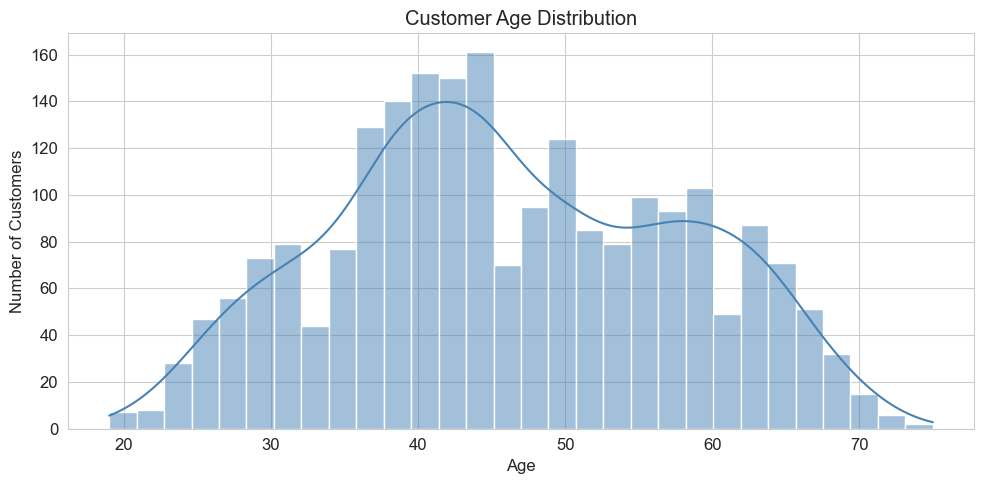

In [71]:
# Age Distribution — cleaned
plt.figure(figsize=(10, 5))
sns.histplot(df['age'], bins=30, color='steelblue', kde=True)
plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

### Finding 1.1 — Age Distribution

The majority of our customers are middle aged, between 35 and 65 years old, 
with the largest concentration around 40 to 45 years old. 
There is a secondary group of customers around 55 to 65 years old.

Business Insight:
The company is primarily serving Gen X and Baby Boomer customers, 
not younger generations. Marketing messaging and channels should 
reflect this — this audience responds better to email and catalog 
marketing rather than platforms like TikTok or Snapchat.

### 1.2 Income Distribution

How much do our customers earn? Understanding income levels helps 
the company know the purchasing power of their customer base and 
whether premium or budget products should be prioritized.

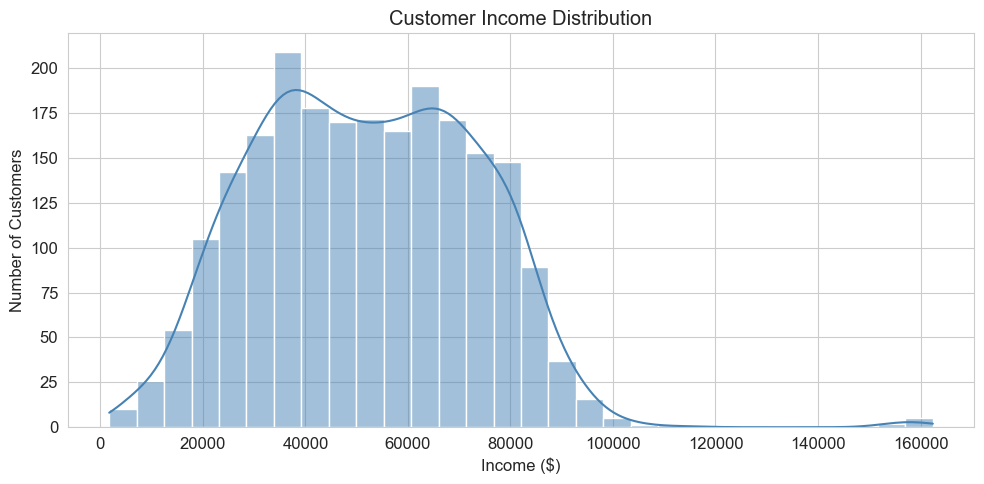

Average Income: $ 51958.81
Median Income: $ 51371.0
Min Income: $ 1730.0
Max Income: $ 162397.0


In [72]:
# Income Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['income'], bins=30, color='steelblue', kde=True)
plt.title('Customer Income Distribution')
plt.xlabel('Income ($)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

# Print key statistics
print('Average Income: $', round(df['income'].mean(), 2))
print('Median Income: $', round(df['income'].median(), 2))
print('Min Income: $', round(df['income'].min(), 2))
print('Max Income: $', round(df['income'].max(), 2))

### Finding 1.2 — Income Distribution

The average customer income is $51,958 with a median of $51,371. 
The fact that the mean and median are very close tells us the 
income distribution is fairly balanced — most customers fall 
in the middle income range between $20,000 and $90,000.

Business Insight:
The company is serving a predominantly middle income customer base. 
This means marketing campaigns should focus on value and quality 
rather than purely luxury positioning. However the small segment 
of high income earners on the right tail may be worth targeting 
separately with premium offers as they likely have higher spending potential.

### 1.3 Education Distribution

What is the education level of our customers? This helps us understand 
how to communicate with them and whether education level influences 
spending behavior.

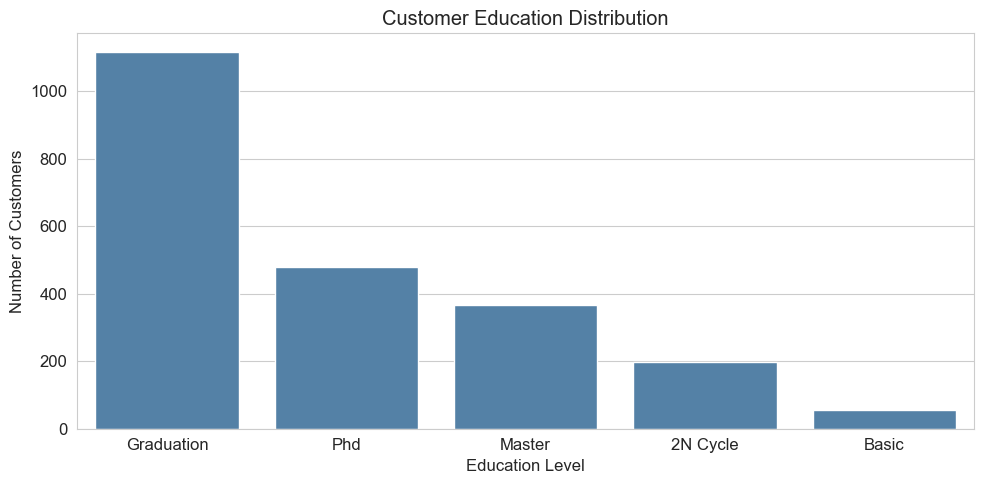

education
Graduation    50.41
Phd           21.70
Master        16.50
2N Cycle       8.95
Basic          2.44
Name: proportion, dtype: float64


In [73]:
# Education Distribution
plt.figure(figsize=(10, 5))
edu_counts = df['education'].value_counts()
sns.barplot(x=edu_counts.index, y=edu_counts.values, color='steelblue')
plt.title('Customer Education Distribution')
plt.xlabel('Education Level')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

# Print percentages
print(round(df['education'].value_counts(normalize=True) * 100, 2))

### Finding 1.3 — Education Distribution

Over 50% of our customers are graduates and nearly 90% have at least 
a graduation level education. PhD and Master holders make up another 
38% combined. Only 2.44% of customers have basic education.

Business Insight:
The company is serving a highly educated customer base. This means 
marketing content can be sophisticated and detailed — educated customers 
tend to research before buying and respond well to data driven messaging, 
quality emphasis, and detailed product information rather than 
simple promotional offers.

### 1.4 Marital Status Distribution

Are our customers mostly single or in a relationship? This helps us 
understand household dynamics and whether family oriented or 
individual focused marketing would be more effective.

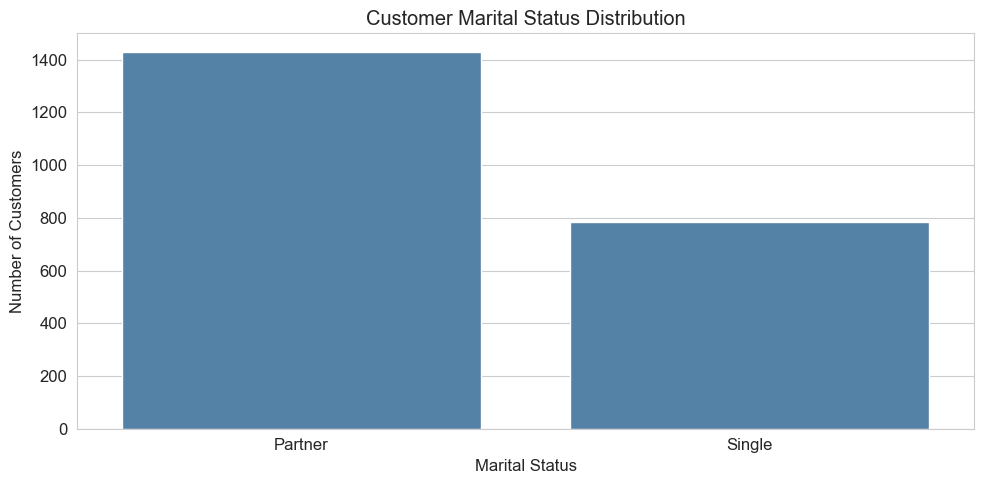

marital_status
Partner    64.56
Single     35.44
Name: proportion, dtype: float64


In [74]:
# Marital Status Distribution
plt.figure(figsize=(10, 5))
marital_counts = df['marital_status'].value_counts()
sns.barplot(x=marital_counts.index, y=marital_counts.values, color='steelblue')
plt.title('Customer Marital Status Distribution')
plt.xlabel('Marital Status')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

# Print percentages
print(round(df['marital_status'].value_counts(normalize=True) * 100, 2))

### Finding 1.4 — Marital Status Distribution

Nearly 65% of our customers are in a relationship — married or living 
with a partner. The remaining 35% are single.

Business Insight:
The majority of our customers are living as couples, which means 
household purchasing decisions may be shared. Marketing campaigns 
should consider couple and family oriented messaging. However the 
35% single segment is still significant enough to warrant targeted 
campaigns for individual customers.

## Objective 2 — Identify High Value Customers

Now that we know who our customers are, we need to identify 
which ones are the most valuable to the business.

High value customers are the ones who spend the most money. 
If we can understand what they have in common, the company can 
target more people like them and increase revenue.

In this section we will look at:
- Does income affect how much customers spend?
- Does age affect spending?
- Does education affect spending?
- Does having children affect spending?

### 2.1 Income vs Total Spend

Do higher income customers spend more? If yes, the company should 
prioritize targeting higher income customers in future campaigns.

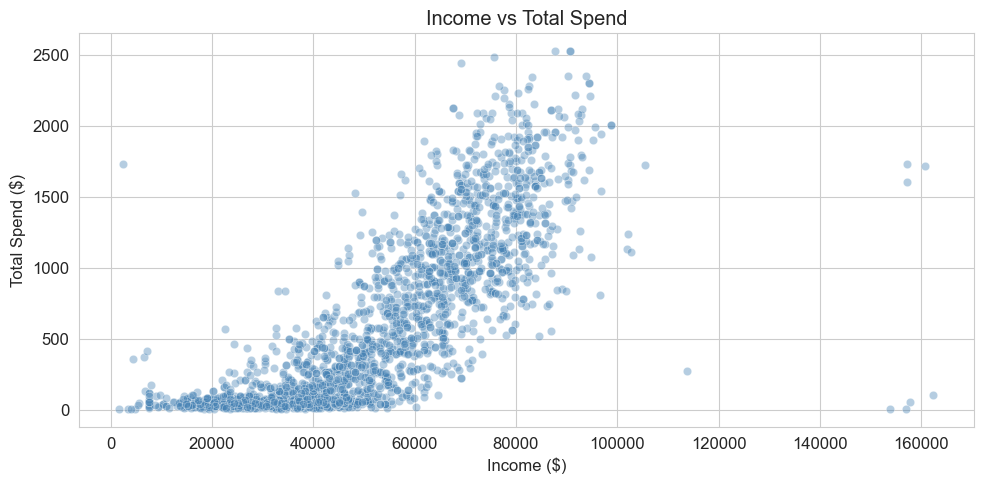

Correlation between Income and Total Spend: 0.79


In [75]:
# Income vs Total Spend
plt.figure(figsize=(10, 5))
sns.scatterplot(x=df['income'], y=df['totalspend'], alpha=0.4, color='steelblue')
plt.title('Income vs Total Spend')
plt.xlabel('Income ($)')
plt.ylabel('Total Spend ($)')
plt.tight_layout()
plt.show()

# Print correlation
corr = df['income'].corr(df['totalspend'])
print(f'Correlation between Income and Total Spend: {round(corr, 2)}')

### Finding 2.1 — Income vs Total Spend

There is a strong positive correlation of 0.79 between customer 
income and total spending. This means that as income increases, 
spending increases significantly.

Business Insight:
Income is the strongest predictor of customer spending in this dataset. 
Higher income customers are clearly the most valuable to the business.

Recommendation:
Future marketing campaigns should prioritize targeting higher income 
customers. Budget spent acquiring and retaining high income customers 
will generate significantly more revenue than the same budget spent 
on lower income segments.

### 2.2 Age vs Total Spend

Does age influence how much customers spend? This helps the company 
understand whether older or younger customers are more valuable 
and whether age should be a targeting factor in future campaigns.

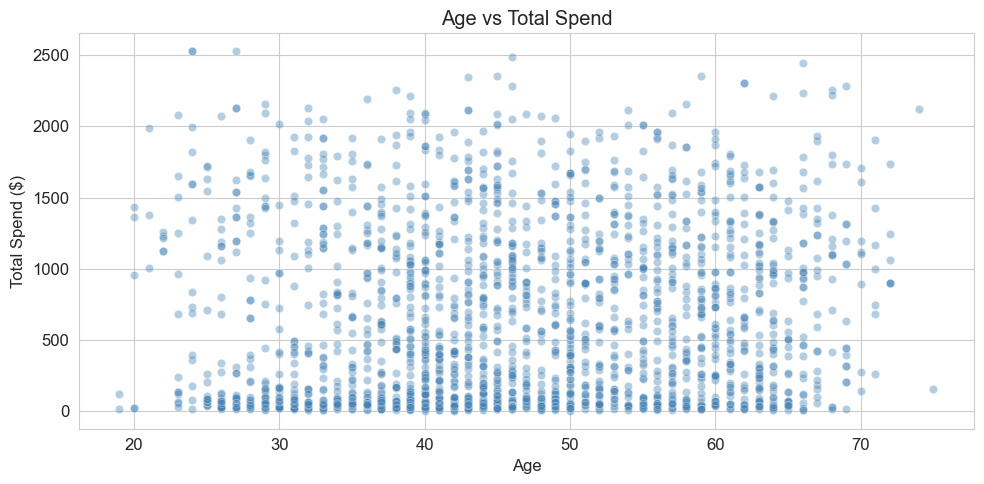

Correlation between Age and Total Spend: 0.12


In [76]:
# Age vs Total Spend
plt.figure(figsize=(10, 5))
sns.scatterplot(x=df['age'], y=df['totalspend'], alpha=0.4, color='steelblue')
plt.title('Age vs Total Spend')
plt.xlabel('Age')
plt.ylabel('Total Spend ($)')
plt.tight_layout()
plt.show()

# Print correlation
corr = df['age'].corr(df['totalspend'])
print(f'Correlation between Age and Total Spend: {round(corr, 2)}')

### Finding 2.2 — Age vs Total Spend

The correlation between age and total spend is only 0.12 — 
which is very weak. The scatter plot confirms this, showing 
high and low spenders spread across all age groups with 
no clear pattern.

Business Insight:
Unlike income, age is not a useful predictor of customer spending. 
High value customers exist at every age group — from 20 year olds 
to 70 year olds.

Recommendation:
The company should not use age as a primary targeting factor 
for high value customers. Income is a far better indicator. 
Age may still be useful for tailoring messaging and 
communication channels but not for identifying who will spend more.

### 2.3 Education vs Total Spend

Does education level influence how much customers spend? 
This helps us understand whether more educated customers 
are also higher spenders.

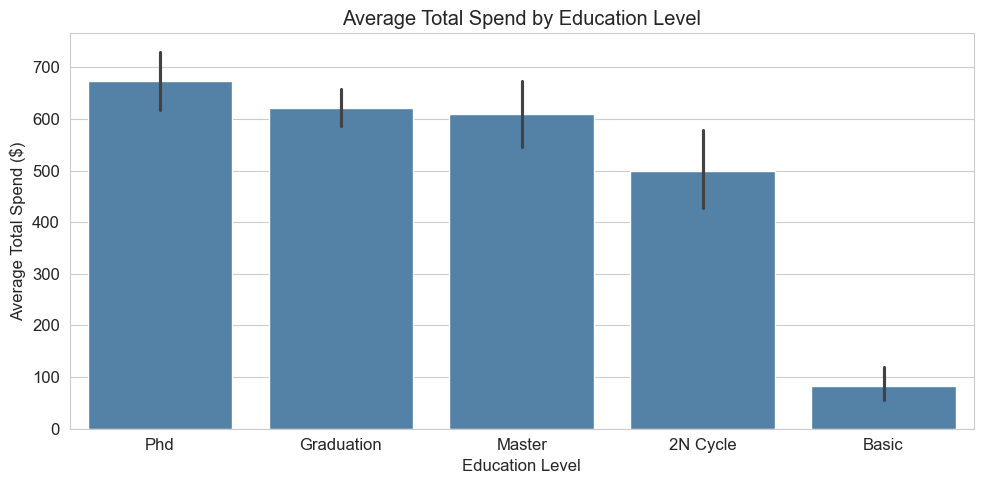

education
Phd           674.28
Graduation    622.19
Master        609.77
2N Cycle      499.49
Basic          81.80
Name: totalspend, dtype: float64


In [77]:
# Education vs Total Spend
plt.figure(figsize=(10, 5))
edu_order = df.groupby('education')['totalspend'].mean().sort_values(ascending=False).index
sns.barplot(x='education', y='totalspend', data=df, order=edu_order, color='steelblue')
plt.title('Average Total Spend by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Average Total Spend ($)')
plt.tight_layout()
plt.show()

# Print average spend by education
print(round(df.groupby('education')['totalspend'].mean().sort_values(ascending=False), 2))

### Finding 2.3 — Education vs Total Spend

There is a clear relationship between education level and spending. 
PhD holders spend the most on average at $674, followed closely by 
Graduation ($622) and Master ($609) holders. 
Customers with Basic education spend only $81 on average — 
more than 8 times less than PhD holders.

Business Insight:
Higher education strongly correlates with higher spending. 
This makes sense because education level is closely tied to 
income level — more educated customers tend to earn more 
and therefore spend more.

Recommendation:
Marketing campaigns targeting PhD, Graduation and Master level 
customers are likely to generate significantly higher returns. 
The Basic education segment generates very little revenue and 
should not be a priority for campaign spend.

### 2.4 Children vs Total Spend

Does having children at home affect how much customers spend? 
This helps us understand whether parents or non-parents 
are more valuable customers.

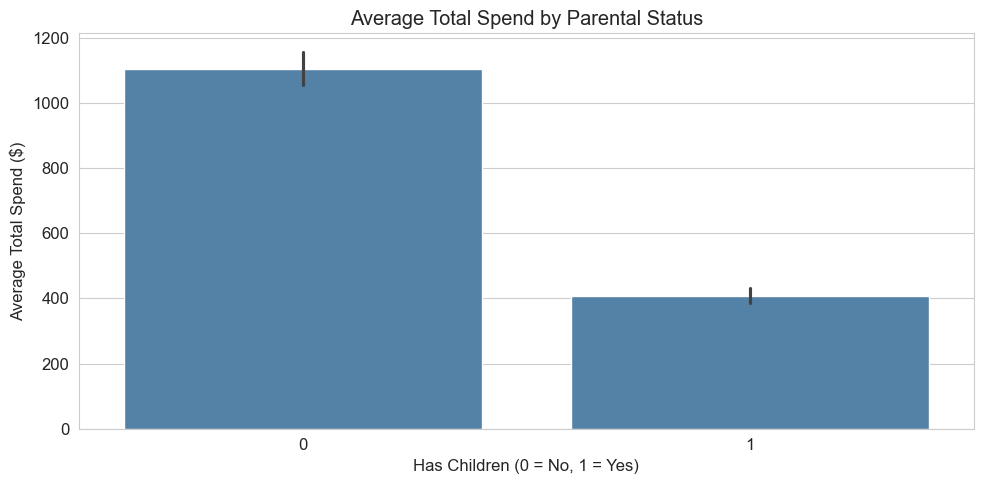

haschildren
0    1104.06
1     408.55
Name: totalspend, dtype: float64


In [78]:
# Children vs Total Spend
plt.figure(figsize=(10, 5))
sns.barplot(x='haschildren', y='totalspend', data=df, color='steelblue')
plt.title('Average Total Spend by Parental Status')
plt.xlabel('Has Children (0 = No, 1 = Yes)')
plt.ylabel('Average Total Spend ($)')
plt.tight_layout()
plt.show()

# Print average spend by parental status
print(round(df.groupby('haschildren')['totalspend'].mean(), 2))

### Finding 2.4 — Children vs Total Spend

Customers without children spend an average of $1,104 compared 
to only $408 for customers with children. This means child-free 
customers spend almost 3 times more than parents.

Business Insight:
Having children at home significantly reduces how much a customer 
spends. This likely reflects the fact that parents allocate a large 
portion of their budget to child related expenses, leaving less 
disposable income for other purchases.

Recommendation:
Customers without children are significantly more valuable to the 
business. Future campaigns should prioritize this segment for 
premium and high value product promotions. For customers with 
children, the company could consider family oriented promotions 
and bundle deals to increase their spending.

## Objective 3 — Analyze Purchasing Behavior

Now that we know who our high value customers are, we need to 
understand how they shop and what they buy.

This section answers two key questions:
- Which products generate the most revenue?
- Which channel do customers prefer — web, store, or catalog?

Understanding this helps the company decide where to invest 
resources and which products to promote more aggressively.

### 3.1 Product Performance

Which products are customers spending the most on? 
This tells us where the company is already strong and 
which products should be prioritized in future campaigns.

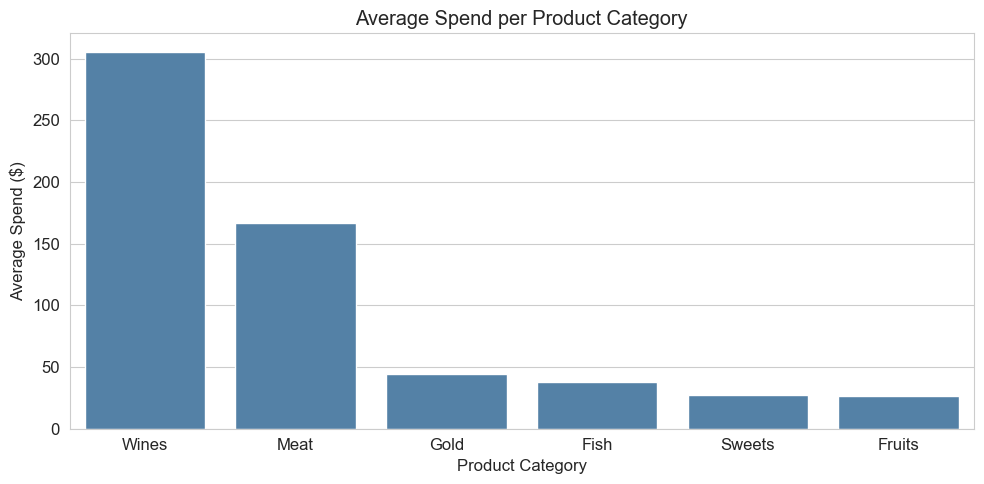

spent_wines     305.29
spent_meat      167.03
spent_gold       43.93
spent_fish       37.65
spent_sweets     27.05
spent_fruits     26.33
dtype: float64


In [79]:
# Average spend per product
product_spend = df[['spent_wines', 'spent_fruits', 'spent_meat', 
                     'spent_fish', 'spent_sweets', 'spent_gold']].mean().sort_values(ascending=False)

# Clean labels for the chart
clean_labels = [label.replace('spent_', '').title() for label in product_spend.index]

plt.figure(figsize=(10, 5))
sns.barplot(x=clean_labels, y=product_spend.values, color='steelblue')
plt.title('Average Spend per Product Category')
plt.xlabel('Product Category')
plt.ylabel('Average Spend ($)')
plt.tight_layout()
plt.show()

print(round(product_spend, 2))

### Finding 3.1 — Product Performance

Wine is by far the highest grossing product category with an average 
spend of $305 per customer — nearly double the second highest category, 
meat products at $167. Gold products, fish, sweets and fruits are all 
significantly lower, each averaging under $45.

Wine and meat together account for the majority of all product revenue 
while fruits and sweets contribute very little.

Business Insight:
The company has two clear revenue drivers — wine and meat. 
The remaining four categories are underperforming significantly.

Recommendation:
The company should double down on wine and meat promotions as these 
are already proven to resonate with customers. For the underperforming 
categories — fruits, sweets and fish — the company should consider 
bundling them with wine or meat products to increase their visibility 
and sales rather than running standalone campaigns for them.

### 3.2 Purchase Channel Preference

How do customers prefer to shop — online, in store, or through 
a catalog? This helps the company understand where to invest 
its resources and which channels to prioritize in future campaigns.

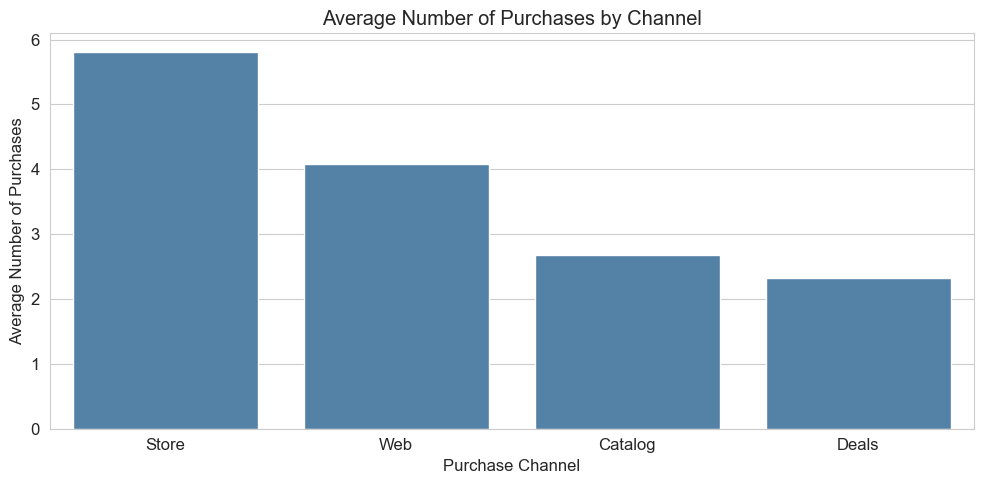

store_purchases      5.81
web_purchases        4.09
catalog_purchases    2.67
deals_purchases      2.32
dtype: float64


In [80]:
# Average purchases per channel
channel_spend = df[['web_purchases', 'catalog_purchases', 
                     'store_purchases', 'deals_purchases']].mean().sort_values(ascending=False)

# Clean labels
clean_labels = ['Store', 'Web', 'Catalog', 'Deals']

plt.figure(figsize=(10, 5))
sns.barplot(x=channel_spend.index, y=channel_spend.values, color='steelblue')
plt.title('Average Number of Purchases by Channel')
plt.xlabel('Purchase Channel')
plt.ylabel('Average Number of Purchases')
plt.xticks(ticks=range(len(clean_labels)), labels=clean_labels)
plt.tight_layout()
plt.show()

# Print values
print(round(channel_spend, 2))

### Finding 3.2 — Purchase Channel Preference

Store purchases are the most popular channel with an average of 
5.81 purchases per customer, followed by web purchases at 4.09. 
Catalog and deals purchases are significantly lower at 2.67 and 
2.32 respectively.

Business Insight:
Customers strongly prefer physical store shopping, but web 
purchases are also substantial — suggesting customers are 
comfortable with both in store and online shopping. 
Catalog shopping is the least preferred channel.

Recommendation:
The company should maintain and invest in its physical store 
experience as it drives the most purchases. At the same time 
the web channel should not be neglected — with 4.09 average 
web purchases it represents a strong secondary channel worth 
investing in. Resources allocated to catalog marketing could 
be reduced and redirected to digital channels for better returns.

## Objective 4 — Evaluate Campaign Performance

Now we evaluate how well the marketing campaigns actually performed.
The company ran 5 campaigns in the past plus a final campaign 
whose response is stored in the 'response' column.

This section answers three key questions:
- How many customers accepted each campaign?
- Which campaign performed the best?
- What kind of customer is most likely to say yes to a campaign?

This is the most critical objective because it directly tells us 
what is working and what is not in the company's marketing strategy.

### 4.1 Campaign Acceptance Rates

How did each campaign perform? Comparing acceptance rates across 
all campaigns tells us which ones were most effective and whether 
campaign performance is improving or declining over time.

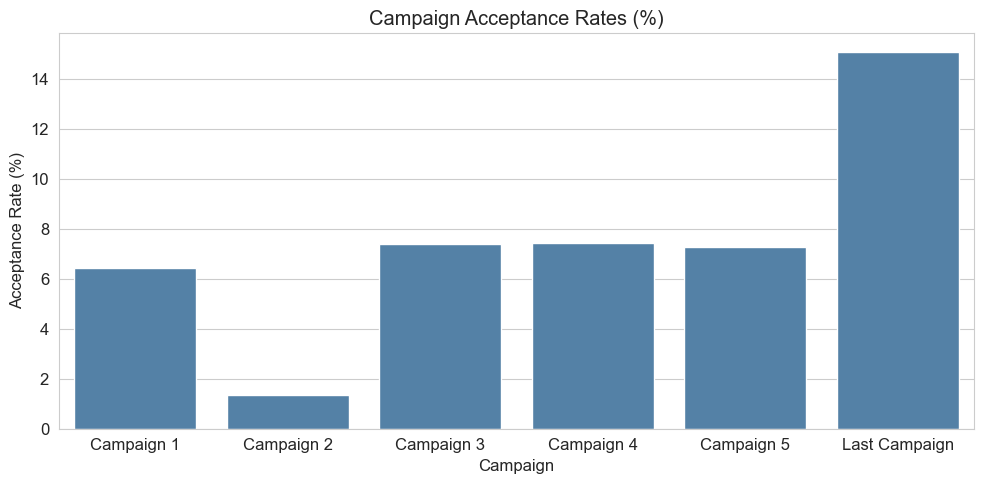

campaign_1     6.42
campaign_2     1.36
campaign_3     7.37
campaign_4     7.41
campaign_5     7.28
response      15.05
dtype: float64


In [81]:
# Campaign acceptance rates
campaign_cols = ['campaign_1', 'campaign_2', 'campaign_3', 
                 'campaign_4', 'campaign_5', 'response']

acceptance_rates = df[campaign_cols].mean() * 100

plt.figure(figsize=(10, 5))
sns.barplot(x=acceptance_rates.index, y=acceptance_rates.values, color='steelblue')
plt.title('Campaign Acceptance Rates (%)')
plt.xlabel('Campaign')
plt.ylabel('Acceptance Rate (%)')
plt.xticks(ticks=range(len(campaign_cols)), 
           labels=['Campaign 1', 'Campaign 2', 'Campaign 3', 
                   'Campaign 4', 'Campaign 5', 'Last Campaign'])
plt.tight_layout()
plt.show()

# Print values
print(round(acceptance_rates, 2))

### Finding 4.1 — Campaign Acceptance Rates

Campaign 2 was the worst performing campaign with only a 1.36% 
acceptance rate. Campaigns 3, 4 and 5 performed similarly at 
around 7% each. The last campaign was the most successful with 
a 15.05% acceptance rate — more than double any previous campaign.

Business Insight:
Overall campaign acceptance rates are low — even the best campaign 
only converted 15% of customers. However the upward trend from 
Campaign 2 onwards and the strong performance of the last campaign 
suggests the company is improving its targeting and messaging over time.

Recommendation:
The company should study what made the last campaign more successful 
than previous ones and replicate those elements in future campaigns. 
Campaign 2 should be analyzed to understand what went wrong and 
those mistakes should be avoided going forward.

### 4.2 Responders vs Non-Responders

The last campaign had the highest acceptance rate at 15.05%. 
But who exactly said yes? 

If we can identify the characteristics of customers who responded, 
the company can target similar customers in future campaigns 
and improve acceptance rates even further.

We will compare responders and non-responders across:
- Income
- Total Spend
- Age
- Having Children

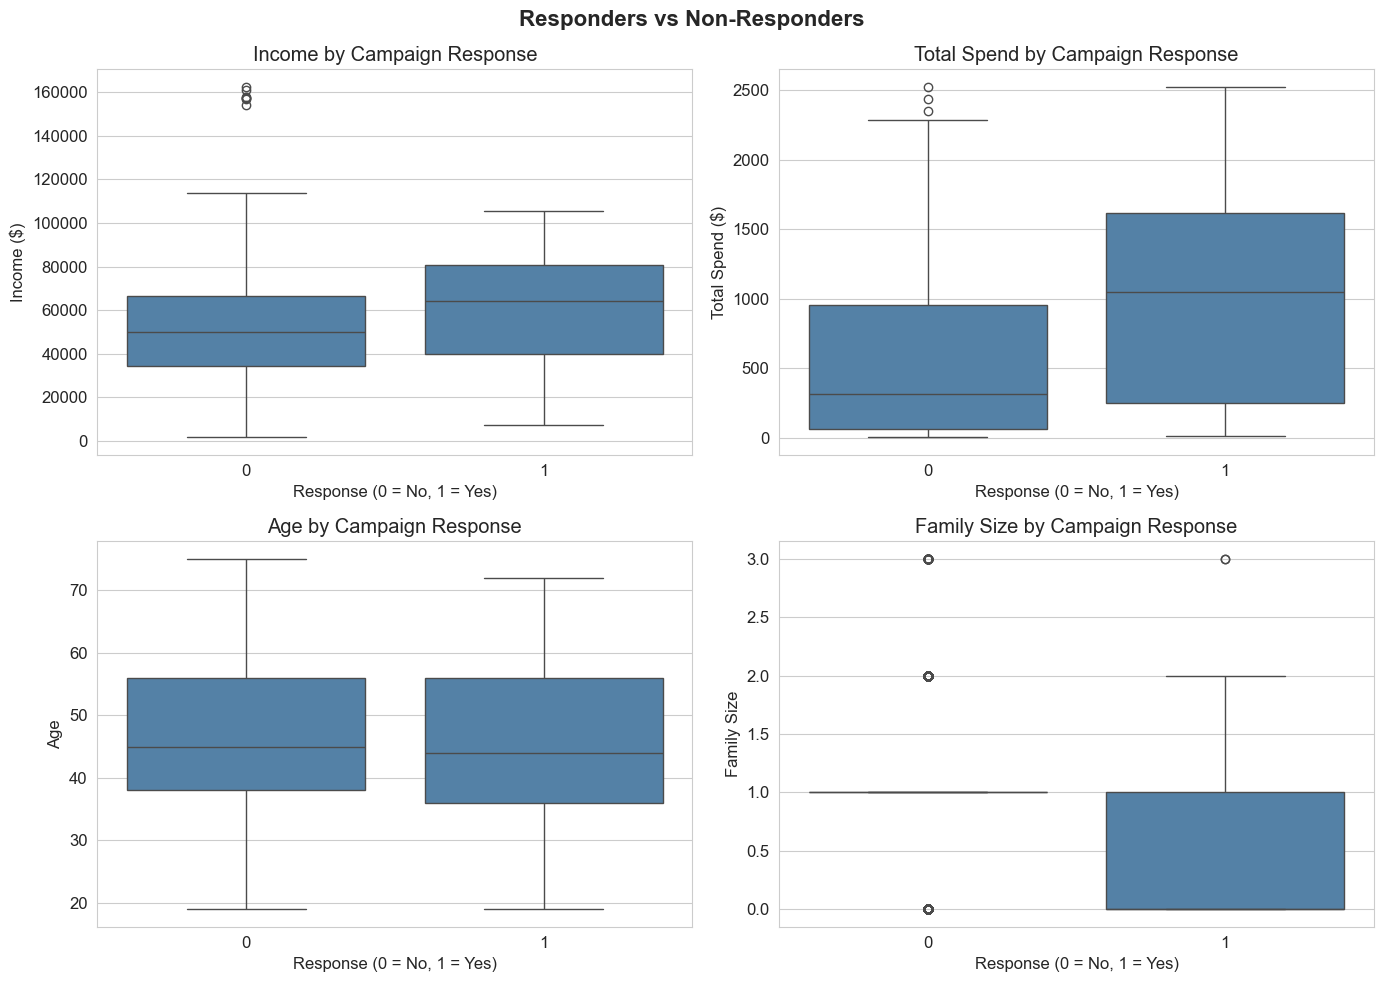

In [82]:
# Compare responders vs non-responders
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Income
sns.boxplot(x='response', y='income', data=df, ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Income by Campaign Response')
axes[0,0].set_xlabel('Response (0 = No, 1 = Yes)')
axes[0,0].set_ylabel('Income ($)')

# Total Spend
sns.boxplot(x='response', y='totalspend', data=df, ax=axes[0,1], color='steelblue')
axes[0,1].set_title('Total Spend by Campaign Response')
axes[0,1].set_xlabel('Response (0 = No, 1 = Yes)')
axes[0,1].set_ylabel('Total Spend ($)')

# Age
sns.boxplot(x='response', y='age', data=df, ax=axes[1,0], color='steelblue')
axes[1,0].set_title('Age by Campaign Response')
axes[1,0].set_xlabel('Response (0 = No, 1 = Yes)')
axes[1,0].set_ylabel('Age')

# Children
sns.boxplot(x='response', y='familysize', data=df, ax=axes[1,1], color='steelblue')
axes[1,1].set_title('Family Size by Campaign Response')
axes[1,1].set_xlabel('Response (0 = No, 1 = Yes)')
axes[1,1].set_ylabel('Family Size')

plt.suptitle('Responders vs Non-Responders', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### Finding 4.2 — Responders vs Non-Responders

Customers who responded to the last campaign are distinctly different 
from those who did not:

- Income: Responders earn noticeably more than non-responders
- Total Spend: Responders spend significantly more — around $1,000 
  median vs $300 for non-responders
- Age: Almost no difference between the two groups
- Family Size: Responders tend to have fewer or no children at home

Business Insight:
The profile of a customer likely to respond to a campaign is clear — 
high income, high spending, and no children. These are exactly the 
same characteristics we identified as high value customers in Objective 2.

Recommendation:
Future campaigns should be laser focused on high income customers 
without children. These customers are not only the most valuable 
but also the most likely to respond to marketing campaigns — 
making them the highest return segment to target.

## Objective 5 — Recommendations

Based on our analysis across all four objectives, we can now provide 
clear data driven recommendations to answer our main business question:

"How can the company improve its marketing strategy using customer data?"

Below we summarize our key findings and translate each one into 
a concrete business recommendation.

### 5.1 Customer Profile Summary

Before recommendations, let us summarize who our customers are 
and who the most valuable ones are.

Our typical customer is:
- Middle aged between 35 and 65 years old
- Middle income earning around $52,000 per year
- Highly educated — 90% have at least a graduation degree
- Mostly in a relationship — 65% have a partner

Our HIGH VALUE customer is:
- Higher income — above $70,000
- No children at home
- Highly educated — PhD, Graduation or Master level
- Spends significantly more across all product categories
- More likely to respond to marketing campaigns

### 5.2 Data Driven Recommendations

---

#### Recommendation 1 — Target High Income Customers

Finding: Income has a 0.79 correlation with total spend — 
the strongest predictor of customer value in this dataset.

Recommendation: Marketing budgets should be concentrated on 
customers earning above $70,000. Acquiring and retaining 
high income customers will generate significantly higher 
revenue than spreading the budget evenly across all segments.

---

#### Recommendation 2 — Prioritize Customers Without Children

Finding: Customers without children spend almost 3 times more 
than customers with children — $1,104 vs $408 on average.

Recommendation: Campaigns for premium and high value products 
should specifically target child-free customers. For customers 
with children, consider family oriented bundle deals to 
increase their relatively low spending.

---

#### Recommendation 3 — Invest More in Wine and Meat Promotions

Finding: Wine accounts for $305 average spend per customer — 
nearly double meat at $167. Together they drive the majority 
of all product revenue.

Recommendation: Increase promotional activity around wine and 
meat products as these are clearly the strongest revenue drivers. 
Bundle underperforming categories like fruits and sweets with 
wine to increase their sales without standalone campaigns.

---

#### Recommendation 4 — Invest in Store and Web Channels

Finding: Store purchases average 5.81 per customer and web 
purchases average 4.09. Catalog and deals are significantly lower.

Recommendation: Continue investing in the physical store 
experience as it drives the most purchases. Strengthen the 
web channel as a strong secondary option. Reduce catalog 
marketing spend and redirect those resources to digital channels.

---

#### Recommendation 5 — Replicate the Last Campaign Strategy

Finding: The last campaign achieved a 15.05% acceptance rate — 
more than double any previous campaign. Campaign 2 was the 
worst at only 1.36%.

Recommendation: Analyze what made the last campaign successful 
and replicate those elements in future campaigns. Study Campaign 2 
to understand what went wrong and avoid repeating those mistakes.

## Conclusion

This analysis set out to answer one question:
"How can the company improve its marketing strategy using customer data?"

The answer is clear:

The company should focus its marketing budget on high income, 
educated, child-free customers who have a strong preference for 
wine and meat products and shop primarily in store and online. 
These customers are not only the highest spenders but also the 
most likely to respond positively to marketing campaigns.

By targeting the right customers, promoting the right products, 
and investing in the right channels — the company can significantly 
improve campaign effectiveness and increase overall revenue.